# Phase 2: Model Development, Training & Iterative Tuning
**Tindihan ni BERB (E-Commerce)** | Dataset: UCI Online Retail | CSE315 Data Science | BSCS 3A

**Prepared by:** Alan Jr. P. Ecalnir | **Date:** November 22, 2026

This notebook uses the Phase 1 outputs and builds one model family per research question:

| RQ | Question | Models |
|---|---|---|
| RQ1 | Which products are bought together? | Association Rules (Apriori, FP-Growth), Network Graph (networkx) |
| RQ2 | What types of customers are there? | Correlation matrix, k-Means Clustering |
| RQ4 | Which customers tend to cancel orders? | Logistic Regression, Linear Discriminant Analysis, Decision Tree, Neural Network (MLP) |
| RQ3 (support) | How much does a customer spend? | Linear Regression on log Monetary |

Every run is written to an experiment log. At the end the notebook exports `Model_Experiment_Log.xlsx` and `model_artifacts.pkl`.

**Files needed in the same folder (or upload them to Colab):** `basket_matrix.csv`, `customer_rfm.csv`, `customer_rfm_scaled.csv`, `cancellations.csv`.

## 0. Setup

In [9]:
import os, time, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import networkx as nx
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 200)
SEED = 42
np.random.seed(SEED)
RUN_BY = "Alan Jr. P. Ecalnir"   # change if someone else reruns the notebook
RUN_DATE = "2026-11-22"          # change to the date of your own run

# Find the data folder (current folder, Colab content folder, or the upload folder)
for DATA_DIR in [".", "/content", "/mnt/user-data/uploads"]:
    if os.path.exists(os.path.join(DATA_DIR, "customer_rfm.csv")):
        break
print("Data folder:", DATA_DIR)

# ---------- Experiment log ----------
EXP_LOG = []
def log_exp(exp_id, rq, model, params, setup, metrics, note="", selected=False):
    EXP_LOG.append({"Exp_ID": exp_id, "Run_By": RUN_BY, "Date_Run": RUN_DATE, "Research_Question": rq, "Model": model,
                    "Hyperparameters": params, "Data_Setup": setup,
                    "Metrics": metrics, "Result_Note": note, "Selected": "Yes" if selected else "No"})

def mark_selected(exp_id, note=None):
    for e in EXP_LOG:
        if e["Exp_ID"] == exp_id:
            e["Selected"] = "Yes"
            if note: e["Result_Note"] = note

Data folder: .


## 1. Load Phase 1 Outputs

In [10]:
basket = pd.read_csv(os.path.join(DATA_DIR, "basket_matrix.csv"), index_col=0).astype(bool)
rfm = pd.read_csv(os.path.join(DATA_DIR, "customer_rfm.csv"))
rfm_scaled_p1 = pd.read_csv(os.path.join(DATA_DIR, "customer_rfm_scaled.csv"))
cancelled = pd.read_csv(os.path.join(DATA_DIR, "cancellations.csv"))
print("basket:", basket.shape, "| rfm:", rfm.shape, "| rfm_scaled:", rfm_scaled_p1.shape, "| cancellations:", cancelled.shape)

# Rebuild the log1p + StandardScaler step so the scaler can be saved for later use.
# We check that it matches the Phase 1 scaled file.
RFM_FEATURES = ["Recency", "Frequency", "Monetary"]
rfm_log = rfm.copy()
for c in ["Recency", "Frequency", "Monetary", "AvgBasketSize", "UniqueProducts"]:
    rfm_log[c] = np.log1p(rfm_log[c])
scaler_rfm = StandardScaler().fit(rfm_log[RFM_FEATURES])
X_rfm = scaler_rfm.transform(rfm_log[RFM_FEATURES])
print("Matches Phase 1 scaled file:", np.allclose(X_rfm, rfm_scaled_p1[RFM_FEATURES].values))

basket: (14905, 100) | rfm: (4334, 6) | rfm_scaled: (4334, 4) | cancellations: (9288, 8)
Matches Phase 1 scaled file: True


## 2. RQ1: Products Bought Together (Association Rules)

**Metrics:** Support (how common the itemset is), Confidence (how often the consequent appears when the antecedent is present), Lift (how much more likely than chance; above 1 means a real link).

**Experiment plan:** Apriori with a grid of `min_support` and `min_confidence`. Lower support gives more rules but includes rarer items. Higher confidence gives fewer but stronger rules. We also compare Apriori and FP-Growth.

In [11]:
itemsets_cache = {}
rows = []
exp_no = 0
for s in [0.01, 0.015, 0.02, 0.03]:
    t0 = time.time()
    fi = apriori(basket, min_support=s, use_colnames=True, max_len=4)
    t_fi = time.time() - t0
    itemsets_cache[s] = fi
    for c in [0.4, 0.5, 0.6, 0.7]:
        exp_no += 1
        rules = association_rules(fi, metric="confidence", min_threshold=c)
        n = len(rules)
        mean_lift = rules["lift"].mean() if n else np.nan
        max_lift = rules["lift"].max() if n else np.nan
        mean_conf = rules["confidence"].mean() if n else np.nan
        eid = f"A{exp_no:02d}"
        log_exp(eid, "RQ1", "Apriori + association_rules (mlxtend)",
                f"min_support={s}; min_confidence={c}; max_len=4",
                f"Basket matrix {basket.shape[0]:,} invoices x {basket.shape[1]} products (no split, unsupervised)",
                f"itemsets={len(fi)}; rules={n}; mean_lift={mean_lift:.2f}; max_lift={max_lift:.2f}; mean_conf={mean_conf:.2f}; runtime_s={t_fi:.2f}",
                "")
        rows.append({"Exp_ID": eid, "min_support": s, "min_confidence": c, "itemsets": len(fi),
                     "rules": n, "mean_lift": mean_lift, "max_lift": max_lift, "mean_conf": mean_conf})
grid_df = pd.DataFrame(rows)
grid_df

,Exp_ID,min_support,min_confidence,itemsets,rules,mean_lift,max_lift,mean_conf
0,A01,0.010,0.400,515,506,9.523,21.846,0.560
1,A02,0.010,0.500,515,337,9.650,21.846,0.617
2,A03,0.010,0.600,515,176,10.205,21.846,0.680
3,A04,0.010,0.700,515,50,11.710,21.310,0.769
4,A05,0.015,0.400,259,184,9.762,21.846,0.547
5,A06,0.015,0.500,259,108,10.581,21.846,0.619
6,A07,0.015,0.600,259,54,12.260,21.846,0.697
7,A08,0.015,0.700,259,21,16.103,21.310,0.794
8,A09,0.020,0.400,161,80,9.270,19.325,0.550
9,A10,0.020,0.500,161,47,10.614,19.325,0.625


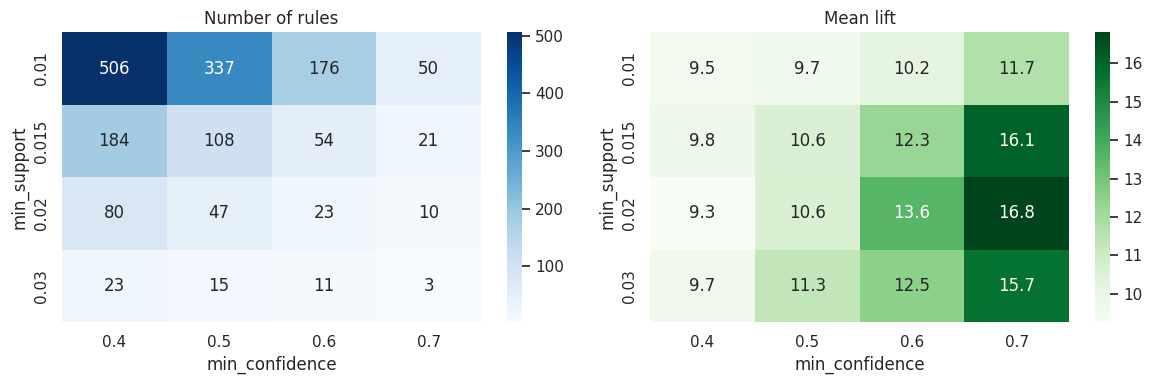

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(grid_df.pivot(index="min_support", columns="min_confidence", values="rules"), annot=True, fmt=".0f", cmap="Blues", ax=ax[0])
ax[0].set_title("Number of rules")
sns.heatmap(grid_df.pivot(index="min_support", columns="min_confidence", values="mean_lift"), annot=True, fmt=".1f", cmap="Greens", ax=ax[1])
ax[1].set_title("Mean lift")
plt.tight_layout(); plt.show()

**Choosing the setting.** Very low support (0.01) with low confidence gives hundreds of rules that are hard to read. A support of 0.015 with a confidence of 0.6 keeps a readable set of strong rules (about 50) with high lift, so it is our selected setting.

In [13]:
# Apriori vs FP-Growth at the selected setting (should give the same rules, runtime may differ)
S_SEL, C_SEL = 0.015, 0.6
t0 = time.time(); fi_ap = apriori(basket, min_support=S_SEL, use_colnames=True, max_len=4); t_ap = time.time() - t0
t0 = time.time(); fi_fp = fpgrowth(basket, min_support=S_SEL, use_colnames=True, max_len=4); t_fp = time.time() - t0
r_ap = association_rules(fi_ap, metric="confidence", min_threshold=C_SEL)
r_fp = association_rules(fi_fp, metric="confidence", min_threshold=C_SEL)
same = len(r_ap) == len(r_fp)
print(f"Apriori: {len(fi_ap)} itemsets, {len(r_ap)} rules, {t_ap:.3f}s | FP-Growth: {len(fi_fp)} itemsets, {len(r_fp)} rules, {t_fp:.3f}s | same rule count: {same}")
log_exp("A17", "RQ1", "FP-Growth + association_rules (mlxtend)",
        f"min_support={S_SEL}; min_confidence={C_SEL}; max_len=4",
        "Same basket matrix as Apriori",
        f"itemsets={len(fi_fp)}; rules={len(r_fp)}; mean_lift={r_fp['lift'].mean():.2f}; runtime_s={t_fp:.3f}",
        f"Same rule count as Apriori ({same}). Apriori runtime {t_ap:.3f}s.")
# mark the Apriori run with the selected setting
sel_id = grid_df[(grid_df.min_support == S_SEL) & (grid_df.min_confidence == C_SEL)]["Exp_ID"].iloc[0]
mark_selected(sel_id, "SELECTED: readable number of strong rules with high lift. Used for the network graph and for bundle suggestions.")
rules = r_ap.copy()
rules["antecedents_str"] = rules["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules["consequents_str"] = rules["consequents"].apply(lambda s: " + ".join(sorted(s)))
top_rules = rules.sort_values(["lift", "confidence"], ascending=False)
top_rules[["antecedents_str", "consequents_str", "support", "confidence", "lift"]].head(15)

Apriori: 259 itemsets, 54 rules, 0.335s | FP-Growth: 259 itemsets, 54 rules, 7.864s | same rule count: True


,antecedents_str,consequents_str,support,confidence,lift
52,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,0.016,0.639,21.846
53,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,0.016,0.773,21.310
50,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,PINK REGENCY TEACUP AND SAUCER,0.016,0.766,20.535
51,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER,0.016,0.902,19.454
19,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,PINK REGENCY TEACUP AND SAUCER,0.018,0.725,19.425
21,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,PINK REGENCY TEACUP AND SAUCER,0.026,0.721,19.325
23,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,0.026,0.701,19.325
22,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,GREEN REGENCY TEACUP AND SAUCER,0.026,0.894,19.294
18,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER,0.018,0.877,18.918
7,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031,0.827,17.846


### 2.1 Network Graph of the Selected Rules

Nodes: 25 | Edges: 36
                                   degree  in_degree_centrality  pagerank
LUNCH BAG PINK POLKADOT                 5                 0.125     0.141
LUNCH BAG RED RETROSPOT                 7                 0.250     0.113
LUNCH BAG  BLACK SKULL.                 5                 0.125     0.073
ALARM CLOCK BAKELIKE RED                3                 0.083     0.073
ALARM CLOCK BAKELIKE GREEN              3                 0.083     0.073
PINK REGENCY TEACUP AND SAUCER          6                 0.125     0.060
ROSES REGENCY TEACUP AND SAUCER         6                 0.125     0.060
GREEN REGENCY TEACUP AND SAUCER         6                 0.125     0.059
GARDENERS KNEELING PAD KEEP CALM        2                 0.042     0.051
GARDENERS KNEELING PAD CUP OF TEA       2                 0.042     0.051


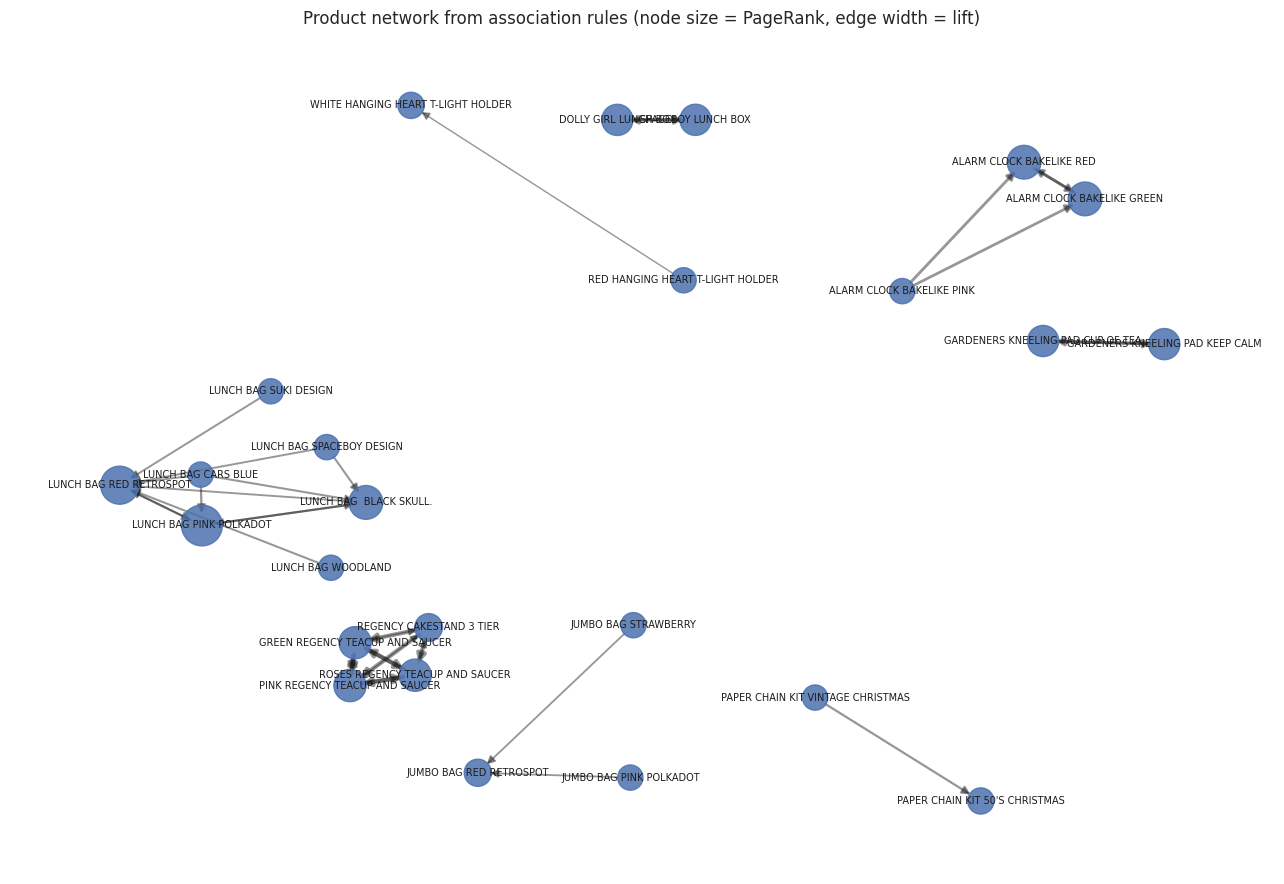

In [14]:
# Directed graph: edge from each antecedent item to each consequent item, weighted by lift
G = nx.DiGraph()
for _, r in rules.iterrows():
    for a in r["antecedents"]:
        for c in r["consequents"]:
            if G.has_edge(a, c):
                G[a][c]["weight"] = max(G[a][c]["weight"], r["lift"])
            else:
                G.add_edge(a, c, weight=r["lift"])
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

centrality = pd.DataFrame({
    "degree": pd.Series(dict(G.degree())),
    "in_degree_centrality": pd.Series(nx.in_degree_centrality(G)),
    "pagerank": pd.Series(nx.pagerank(G, weight="weight")),
}).sort_values("pagerank", ascending=False)
print(centrality.head(10))

plt.figure(figsize=(13, 9))
pos = nx.spring_layout(G, k=0.9, seed=SEED)
sizes = [300 + 4000 * centrality.loc[n, "pagerank"] for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color="#4c72b0", alpha=0.85)
nx.draw_networkx_edges(G, pos, width=[0.4 + G[u][v]["weight"] / 8 for u, v in G.edges()], alpha=0.45, arrows=True, arrowsize=12)
nx.draw_networkx_labels(G, pos, font_size=7)
plt.title("Product network from association rules (node size = PageRank, edge width = lift)")
plt.axis("off"); plt.tight_layout(); plt.show()
log_exp("N01", "RQ1", "Network Graph (networkx DiGraph)",
        f"Edges from rules with support>={S_SEL}, confidence>={C_SEL}; edge weight=lift; layout=spring(seed={SEED})",
        "Rules from selected Apriori run",
        f"nodes={G.number_of_nodes()}; edges={G.number_of_edges()}; top PageRank item={centrality.index[0]}",
        "Hub products are good anchors for bundles and bought-together suggestions.", selected=True)

## 3. RQ2: Customer Types (Correlation Matrix and k-Means)

### 3.1 Correlation matrix
Already shown in Phase 1. We repeat it on the log-transformed features to confirm the choice of Recency, Frequency and Monetary.

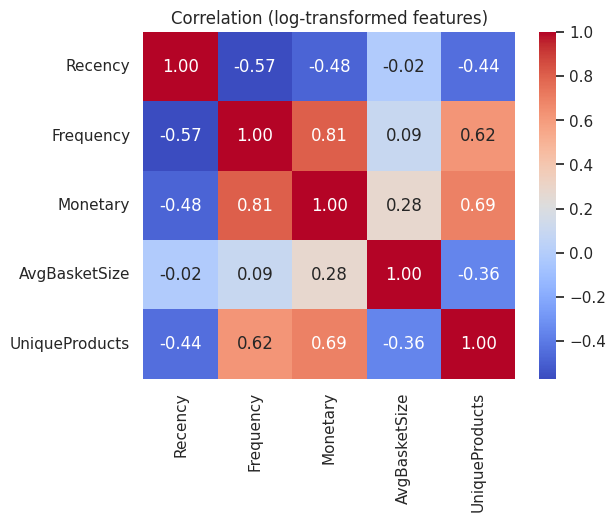

In [15]:
corr = rfm_log.drop(columns="CustomerID").corr()
plt.figure(figsize=(6, 4.5)); sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f"); plt.title("Correlation (log-transformed features)"); plt.show()
log_exp("C01", "RQ2", "Correlation matrix (pandas)", "method=pearson; features log1p-transformed",
        f"{len(rfm):,} customers x 5 features", f"corr(Frequency, UniqueProducts)={corr.loc['Frequency','UniqueProducts']:.2f}; corr(Frequency, Monetary)={corr.loc['Frequency','Monetary']:.2f}",
        "Confirms Recency, Frequency, Monetary as clustering features.", selected=True)

### 3.2 k-Means: choosing the number of clusters
We try k from 2 to 10 with k-means++ and compare inertia (elbow), silhouette (higher is better), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better).

    k   inertia  silhouette  davies_bouldin  calinski_harabasz
0   2 6,477.091       0.433           0.892          4,363.992
1   3 4,861.456       0.338           1.046          3,626.265
2   4 3,932.533       0.338           1.014          3,328.840
3   5 3,290.462       0.317           0.984          3,194.192
4   6 2,850.014       0.314           1.009          3,083.342
5   7 2,547.561       0.309           0.980          2,959.468
6   8 2,334.575       0.302           0.993          2,823.865
7   9 2,156.839       0.280           1.022          2,718.418
8  10 2,005.875       0.277           1.026          2,633.817


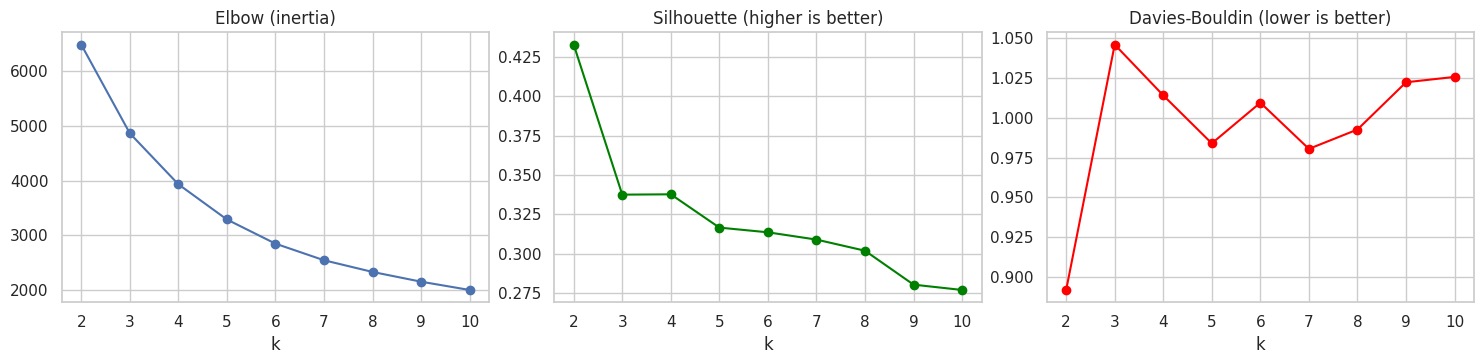

In [16]:
km_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X_rfm)
    sil = silhouette_score(X_rfm, km.labels_)
    dbi = davies_bouldin_score(X_rfm, km.labels_)
    ch = calinski_harabasz_score(X_rfm, km.labels_)
    km_rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil, "davies_bouldin": dbi, "calinski_harabasz": ch})
    log_exp(f"K{k-1:02d}", "RQ2", "k-Means (sklearn)", f"n_clusters={k}; init=k-means++; n_init=10; random_state={SEED}",
            "Scaled RFM (log1p + StandardScaler), 4,334 customers, unsupervised",
            f"inertia={km.inertia_:.0f}; silhouette={sil:.3f}; davies_bouldin={dbi:.3f}; calinski_harabasz={ch:.0f}", "")
km_df = pd.DataFrame(km_rows)
print(km_df)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(km_df.k, km_df.inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_df.k, km_df.silhouette, marker="o", color="green"); ax[1].set_title("Silhouette (higher is better)")
ax[2].plot(km_df.k, km_df.davies_bouldin, marker="o", color="red"); ax[2].set_title("Davies-Bouldin (lower is better)")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [17]:
# Extra experiments: different initialization and a 5-feature version, to test stability
rfm5_cols = ["Recency", "Frequency", "Monetary", "AvgBasketSize", "UniqueProducts"]
X5 = StandardScaler().fit_transform(rfm_log[rfm5_cols])
for eid, name, X, init in [("K10", "RFM 3 features, init=random", X_rfm, "random"),
                           ("K11", "5 features (adds AvgBasketSize, UniqueProducts), init=k-means++", X5, "k-means++")]:
    km = KMeans(n_clusters=4, init=init, n_init=10, random_state=SEED).fit(X)
    sil = silhouette_score(X, km.labels_); dbi = davies_bouldin_score(X, km.labels_)
    log_exp(eid, "RQ2", "k-Means (sklearn)", f"n_clusters=4; init={init}; n_init=10; random_state={SEED}",
            name, f"inertia={km.inertia_:.0f}; silhouette={sil:.3f}; davies_bouldin={dbi:.3f}",
            "Stability check against the main k=4 run.")
    print(eid, name, "silhouette", round(sil, 3))

K10 RFM 3 features, init=random silhouette 0.338
K11 5 features (adds AvgBasketSize, UniqueProducts), init=k-means++ silhouette 0.252


### 3.3 Stability check
k-Means can change with the random start. We fit k = 4 with 10 different seeds and compare each result with the seed 42 result using the Adjusted Rand Index (1.0 means identical groups).

In [18]:
from sklearn.metrics import adjusted_rand_score
ref = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=SEED).fit(X_rfm).labels_
aris = []
for sd in range(10):
    lab = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=sd).fit(X_rfm).labels_
    aris.append(adjusted_rand_score(ref, lab))
print("ARI vs seed 42 over 10 seeds: mean", round(np.mean(aris), 3), "| min", round(np.min(aris), 3))
log_exp("K12", "RQ2", "k-Means stability (10 seeds)", "n_clusters=4; init=k-means++; n_init=10; seeds 0 to 9",
        "Scaled RFM, 4,334 customers", f"ARI mean={np.mean(aris):.3f}; ARI min={np.min(aris):.3f}",
        "Values close to 1 mean the segments are stable and not a random accident.")

ARI vs seed 42 over 10 seeds: mean 0.974 | min 0.951


**Choosing k.** The silhouette score is highest at k = 2, but that only splits customers into active and inactive, which is too simple for promos. Silhouette is the same for k = 3 and k = 4, and k = 4 gives one more useful group (loyal, regular, new, and lapsed buyers), so we select k = 4.

In [19]:
K_SEL = 4
kmeans_final = KMeans(n_clusters=K_SEL, init="k-means++", n_init=10, random_state=SEED).fit(X_rfm)
rfm_seg = rfm.copy(); rfm_seg["Cluster"] = kmeans_final.labels_
profile = rfm_seg.groupby("Cluster").agg(Customers=("CustomerID", "count"), Recency_median=("Recency", "median"),
          Frequency_median=("Frequency", "median"), Monetary_median=("Monetary", "median"), Monetary_total=("Monetary", "sum"))
profile["Customer_share_%"] = profile["Customers"] / len(rfm_seg) * 100
profile["Revenue_share_%"] = profile["Monetary_total"] / profile["Monetary_total"].sum() * 100
profile

,Customers,Recency_median,Frequency_median,Monetary_median,Monetary_total,Customer_share_%,Revenue_share_%
Cluster,,,,,,,
0,840,17.000,2.000,459.180,"446,683.580",19.382,5.109
1,1636,177.000,1.000,299.680,"575,280.610",37.748,6.579
2,1174,52.000,4.000,"1,369.240","2,123,880.770",27.088,24.290
3,684,8.000,10.000,"3,719.110","5,598,068.680",15.782,64.022


In [20]:
# Name each cluster from its profile using ranks (works even if cluster numbers change)
def name_clusters(p):
    names = {}
    loyal = p["Monetary_median"].idxmax(); names[loyal] = "Loyal / Big Spenders"
    rest = p.drop(index=loyal)
    lapsed = rest["Recency_median"].idxmax(); names[lapsed] = "Inactive / Lapsed"
    rest = rest.drop(index=lapsed)
    regular = rest["Monetary_median"].idxmax(); names[regular] = "Regular Buyers"
    for c in rest.index:
        if c != regular: names[c] = "New / Recent Low Spenders"
    return names
seg_names = name_clusters(profile)
print(seg_names)
profile["Segment"] = profile.index.map(seg_names)
rfm_seg["Segment"] = rfm_seg["Cluster"].map(seg_names)
profile[["Segment", "Customers", "Customer_share_%", "Revenue_share_%", "Recency_median", "Frequency_median", "Monetary_median"]]

{np.int32(3): 'Loyal / Big Spenders', np.int32(1): 'Inactive / Lapsed', np.int32(2): 'Regular Buyers', 0: 'New / Recent Low Spenders'}


,Segment,Customers,Customer_share_%,Revenue_share_%,Recency_median,Frequency_median,Monetary_median
Cluster,,,,,,,
0,New / Recent Low Spenders,840,19.382,5.109,17.000,2.000,459.180
1,Inactive / Lapsed,1636,37.748,6.579,177.000,1.000,299.680
2,Regular Buyers,1174,27.088,24.290,52.000,4.000,"1,369.240"
3,Loyal / Big Spenders,684,15.782,64.022,8.000,10.000,"3,719.110"


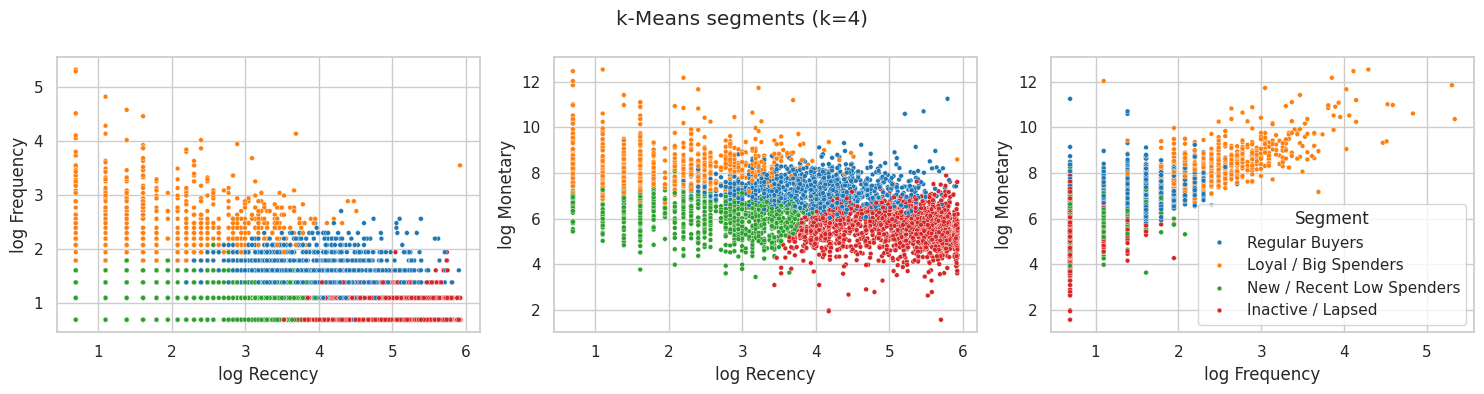

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (x, y) in zip(ax, [("Recency", "Frequency"), ("Recency", "Monetary"), ("Frequency", "Monetary")]):
    sns.scatterplot(x=np.log1p(rfm_seg[x]), y=np.log1p(rfm_seg[y]), hue=rfm_seg["Segment"], palette="tab10", s=12, ax=a, legend=(a is ax[2]))
    a.set_xlabel(f"log {x}"); a.set_ylabel(f"log {y}")
plt.suptitle("k-Means segments (k=4)"); plt.tight_layout(); plt.show()

sil_final = silhouette_score(X_rfm, kmeans_final.labels_)
mark_selected("K03", f"SELECTED: k=4. Segments: {', '.join(seg_names.values())}. Silhouette {sil_final:.3f}.")

## 4. RQ4: Predicting Which Customers Cancel Orders (Classification)

**Target:** `Has_Cancelled` = 1 if the customer has at least one cancelled invoice in the cancellation table, otherwise 0. Cancellation rows without a CustomerID cannot be linked to a customer and are skipped.

**Features:** Recency, Frequency, Monetary, AvgBasketSize, UniqueProducts (all log1p transformed, then scaled inside each pipeline so there is no leakage from the validation or test sets).

**Note on interpretation:** customers who order more often have more chances to cancel, so Frequency is expected to be a strong predictor. The model is meant to flag customers to watch, not to prove a cause.

**Data split:** 60% train, 20% validation, 20% test (stratified, random_state = 42). We tune on validation and report the final result once on the test set.

In [22]:
cancel_ids = set(cancelled["CustomerID"].dropna().astype(int))
data = rfm_log.copy()
data["Has_Cancelled"] = rfm["CustomerID"].isin(cancel_ids).astype(int)
print(data["Has_Cancelled"].value_counts(), "\nCancel rate:", round(data["Has_Cancelled"].mean(), 3))

FEATS = ["Recency", "Frequency", "Monetary", "AvgBasketSize", "UniqueProducts"]
X, y = data[FEATS], data["Has_Cancelled"]
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)  # 0.25 of 80% = 20%
print("train / val / test:", len(X_train), len(X_val), len(X_test))
SPLIT = f"train={len(X_train)}, val={len(X_val)}, test={len(X_test)} (stratified 60/20/20, seed {SEED})"

Has_Cancelled
0    2781
1    1553
Name: count, dtype: int64 
Cancel rate: 0.358
train / val / test: 2600 867 867


In [23]:
def evaluate(model, Xs, ys):
    pred = model.predict(Xs); proba = model.predict_proba(Xs)[:, 1]
    return {"accuracy": accuracy_score(ys, pred), "precision": precision_score(ys, pred, zero_division=0),
            "recall": recall_score(ys, pred), "f1": f1_score(ys, pred), "roc_auc": roc_auc_score(ys, proba)}

def fmt(m): return "; ".join(f"{k}={v:.3f}" for k, v in m.items())

# Baseline: always predict the majority class
base_acc = max(y_val.mean(), 1 - y_val.mean())
log_exp("P00", "RQ4", "Baseline (majority class)", "predict No Cancel for all", SPLIT,
        f"val_accuracy={base_acc:.3f}; precision=0; recall=0; f1=0; roc_auc=0.500", "Any useful model must beat this.")

experiments = []   # (exp_id, name, params_str, pipeline)
def add(exp_id, name, params_str, pipe): experiments.append((exp_id, name, params_str, pipe))

n = 0
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, "balanced"]:
        n += 1
        add(f"P{n:02d}", "Logistic Regression", f"C={C}; class_weight={cw}; max_iter=1000",
            Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=C, class_weight=cw, max_iter=1000, random_state=SEED))]))
for solver, shr in [("svd", None), ("lsqr", "auto")]:
    n += 1
    add(f"P{n:02d}", "Linear Discriminant Analysis", f"solver={solver}; shrinkage={shr}",
        Pipeline([("sc", StandardScaler()), ("m", LinearDiscriminantAnalysis(solver=solver, shrinkage=shr))]))
for d in [2, 3, 4, 5, 6, 8]:
    n += 1
    add(f"P{n:02d}", "Decision Tree", f"max_depth={d}; min_samples_leaf=20; criterion=gini",
        Pipeline([("m", DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=SEED))]))
for hl, alpha in [((8,), 0.001), ((16,), 0.001), ((16, 8), 0.001), ((16, 8), 0.01), ((32, 16), 0.01)]:
    n += 1
    add(f"P{n:02d}", "Neural Network (MLPClassifier)", f"hidden_layer_sizes={hl}; activation=relu; alpha={alpha}; early_stopping=True; max_iter=500",
        Pipeline([("sc", StandardScaler()), ("m", MLPClassifier(hidden_layer_sizes=hl, alpha=alpha, early_stopping=True, max_iter=500, random_state=SEED))]))

res = []
for exp_id, name, ps, pipe in experiments:
    pipe.fit(X_train, y_train)
    mt, mv = evaluate(pipe, X_train, y_train), evaluate(pipe, X_val, y_val)
    log_exp(exp_id, "RQ4", name, ps, SPLIT, f"TRAIN {fmt(mt)} || VAL {fmt(mv)}", "")
    res.append({"Exp_ID": exp_id, "Model": name, "Params": ps, "train_f1": mt["f1"], "val_acc": mv["accuracy"],
                "val_prec": mv["precision"], "val_recall": mv["recall"], "val_f1": mv["f1"], "val_auc": mv["roc_auc"]})
res_df = pd.DataFrame(res)
res_df.sort_values("val_auc", ascending=False).reset_index(drop=True)

,Exp_ID,Model,Params,train_f1,val_acc,val_prec,val_recall,val_f1,val_auc
0,P08,Logistic Regression,C=10; class_weight=balanced; max_iter=1000,0.660,0.723,0.599,0.688,0.641,0.798
1,P06,Logistic Regression,C=1; class_weight=balanced; max_iter=1000,0.660,0.723,0.599,0.688,0.641,0.798
2,P07,Logistic Regression,C=10; class_weight=None; max_iter=1000,0.600,0.752,0.711,0.521,0.601,0.798
3,P05,Logistic Regression,C=1; class_weight=None; max_iter=1000,0.600,0.752,0.712,0.518,0.600,0.798
4,P04,Logistic Regression,C=0.1; class_weight=balanced; max_iter=1000,0.657,0.723,0.599,0.688,0.641,0.798
5,P03,Logistic Regression,C=0.1; class_weight=None; max_iter=1000,0.598,0.750,0.708,0.514,0.596,0.797
6,P09,Linear Discriminant Analysis,solver=svd; shrinkage=None,0.588,0.752,0.720,0.505,0.594,0.797
7,P10,Linear Discriminant Analysis,solver=lsqr; shrinkage=auto,0.589,0.752,0.718,0.508,0.595,0.796
8,P02,Logistic Regression,C=0.01; class_weight=balanced; max_iter=1000,0.656,0.720,0.598,0.666,0.630,0.793
9,P19,Neural Network (MLPClassifier),"hidden_layer_sizes=(16, 8); activation=relu; a...",0.631,0.737,0.661,0.547,0.599,0.793


**Model selection rule:** highest validation ROC-AUC (it does not depend on the 0.5 cutoff). Validation F1 and the gap between train and validation F1 are checked for overfitting.

In [24]:
best_row = res_df.sort_values("val_auc", ascending=False).iloc[0]
best_id = best_row["Exp_ID"]
print("Best on validation:", best_id, best_row["Model"], best_row["Params"], "| val AUC", round(best_row["val_auc"], 3))
best_by_family = res_df.loc[res_df.groupby("Model")["val_auc"].idxmax()][["Exp_ID", "Model", "Params", "val_f1", "val_auc"]]
print(best_by_family.to_string(index=False))

# Refit the winner on train only (already fitted) and report on the test set once
pipe_best = [p for e, _, _, p in experiments if e == best_id][0]
m_test = evaluate(pipe_best, X_test, y_test)
print("TEST:", fmt(m_test))
log_exp("P99", "RQ4", f"FINAL TEST: {best_row['Model']} ({best_id})", best_row["Params"], SPLIT,
        f"TEST {fmt(m_test)}", "Final unbiased estimate on the untouched test set. Test set used only once.", selected=True)
mark_selected(best_id, "SELECTED on validation ROC-AUC.")

Best on validation: P08 Logistic Regression C=10; class_weight=balanced; max_iter=1000 | val AUC 0.798
Exp_ID                          Model                                                                                      Params  val_f1  val_auc
   P15                  Decision Tree                                            max_depth=6; min_samples_leaf=20; criterion=gini   0.614    0.788
   P09   Linear Discriminant Analysis                                                                  solver=svd; shrinkage=None   0.594    0.797
   P08            Logistic Regression                                                  C=10; class_weight=balanced; max_iter=1000   0.641    0.798
   P19 Neural Network (MLPClassifier) hidden_layer_sizes=(16, 8); activation=relu; alpha=0.001; early_stopping=True; max_iter=500   0.599    0.793
TEST: accuracy=0.712; precision=0.581; recall=0.704; f1=0.637; roc_auc=0.771


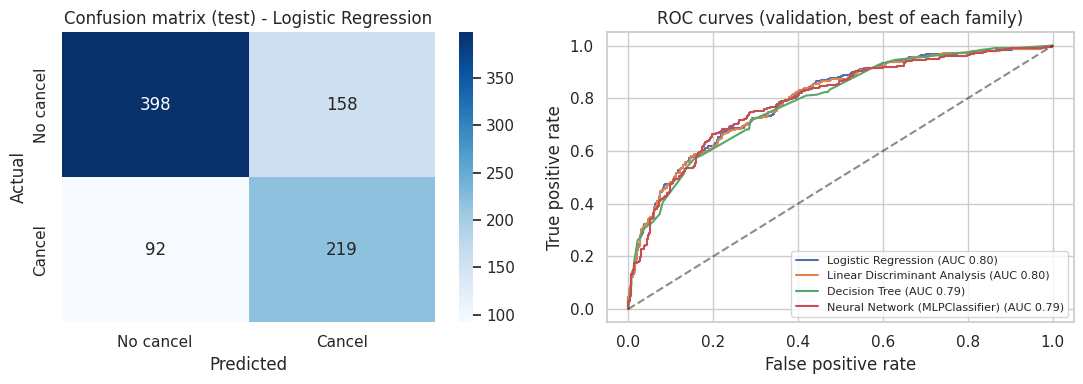

In [25]:
pred_test = pipe_best.predict(X_test)
cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0], xticklabels=["No cancel", "Cancel"], yticklabels=["No cancel", "Cancel"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title(f"Confusion matrix (test) - {best_row['Model']}")
for exp_id, name, ps, pipe in experiments:
    if exp_id in set(best_by_family["Exp_ID"]):
        fpr, tpr, _ = roc_curve(y_val, pipe.predict_proba(X_val)[:, 1])
        ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_val, pipe.predict_proba(X_val)[:, 1]):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5); ax[1].set_title("ROC curves (validation, best of each family)")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.1 Cross-validation check
The validation split is one lucky or unlucky draw, so we confirm the best model of each family with 5-fold stratified cross-validation on the train and validation data together. The test set stays untouched.

In [26]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for i, (_, r) in enumerate(best_by_family.reset_index(drop=True).iterrows(), start=1):
    pipe = clone([p for e, _, _, p in experiments if e == r["Exp_ID"]][0])
    cvr = cross_validate(pipe, X_tmp, y_tmp, cv=skf, scoring=scoring)
    row = {"Exp_ID": f"CV{i}", "Model": r["Model"], "Source": r["Exp_ID"]}
    for m in scoring:
        row[m + "_mean"] = cvr["test_" + m].mean(); row[m + "_std"] = cvr["test_" + m].std()
    cv_rows.append(row)
    log_exp(f"CV{i}", "RQ4", f"5-fold CV: {r['Model']} (from {r['Exp_ID']})", r["Params"],
            f"5-fold stratified CV on train+val ({len(X_tmp)} customers), seed {SEED}",
            "; ".join(f"{m}={cvr['test_' + m].mean():.3f}+-{cvr['test_' + m].std():.3f}" for m in scoring),
            "Confirms the validation ranking is not a lucky split.")
cv_df = pd.DataFrame(cv_rows)
cv_df[["Exp_ID", "Model", "accuracy_mean", "f1_mean", "f1_std", "roc_auc_mean", "roc_auc_std"]]

,Exp_ID,Model,accuracy_mean,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,CV1,Decision Tree,0.739,0.596,0.018,0.782,0.017
1,CV2,Linear Discriminant Analysis,0.746,0.587,0.013,0.796,0.004
2,CV3,Logistic Regression,0.733,0.654,0.013,0.797,0.004
3,CV4,Neural Network (MLPClassifier),0.740,0.610,0.007,0.784,0.018


                LogReg_coef (scaled)  DecisionTree_importance
Recency                        0.094                    0.036
Frequency                      0.700                    0.175
Monetary                       0.980                    0.667
AvgBasketSize                 -0.121                    0.069
UniqueProducts                -0.262                    0.052


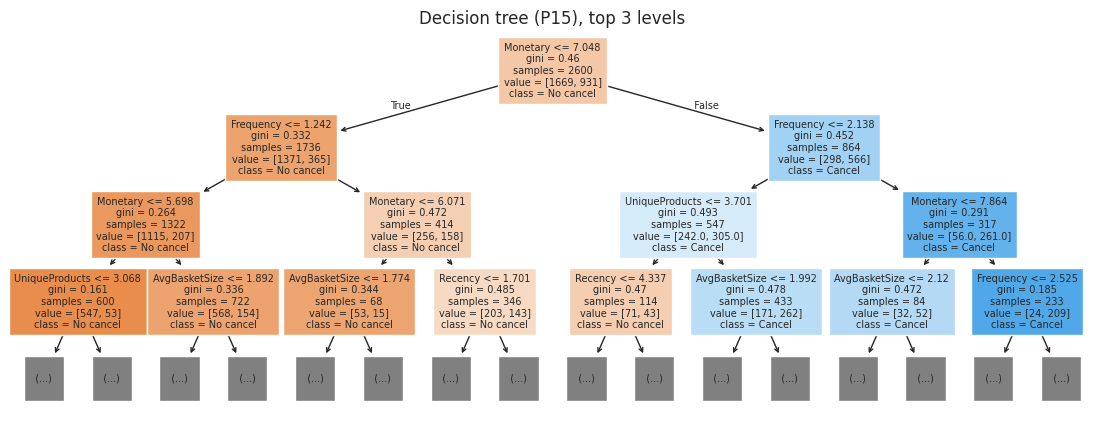

In [27]:
# Which features matter? (logistic regression coefficients and decision tree importances for interpretation)
lr_id = best_by_family[best_by_family.Model == "Logistic Regression"]["Exp_ID"].iloc[0]
lr_pipe = [p for e, _, _, p in experiments if e == lr_id][0]
dt_id = best_by_family[best_by_family.Model == "Decision Tree"]["Exp_ID"].iloc[0]
dt_pipe = [p for e, _, _, p in experiments if e == dt_id][0]
imp = pd.DataFrame({"LogReg_coef (scaled)": lr_pipe.named_steps["m"].coef_[0],
                    "DecisionTree_importance": dt_pipe.named_steps["m"].feature_importances_}, index=FEATS)
print(imp)
plt.figure(figsize=(14, 5))
plot_tree(dt_pipe.named_steps["m"], feature_names=FEATS, class_names=["No cancel", "Cancel"], filled=True, fontsize=7, max_depth=3)
plt.title(f"Decision tree ({dt_id}), top 3 levels"); plt.show()

## 5. Supporting Model: Linear Regression on Customer Spending (RQ2 and RQ3)
Predict log Monetary from Recency, Frequency, AvgBasketSize and UniqueProducts. This shows which behaviors drive spending. We use the same 60/20/20 split.

train {'r2': 0.8711440042196722, 'rmse': 0.45561314389486346, 'mae': 0.33210536739854907} 
val {'r2': 0.8785858270641511, 'rmse': 0.4374335206189036, 'mae': 0.3229609336351462} 
test {'r2': 0.8768712105476146, 'rmse': 0.42326765119835325, 'mae': 0.3130818068485687}
Recency          0.035
Frequency        0.495
AvgBasketSize    0.604
UniqueProducts   0.794
dtype: float64


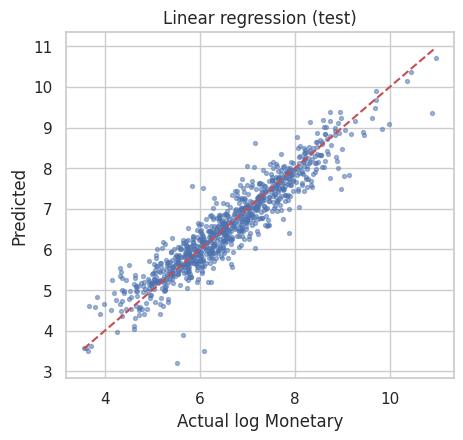

In [28]:
reg_feats = ["Recency", "Frequency", "AvgBasketSize", "UniqueProducts"]
Xr, yr = data[reg_feats], data["Monetary"]
Xr_tmp, Xr_test, yr_tmp, yr_test = train_test_split(Xr, yr, test_size=0.20, random_state=SEED)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(Xr_tmp, yr_tmp, test_size=0.25, random_state=SEED)
lin = Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]).fit(Xr_train, yr_train)
def reg_metrics(m, Xs, ys):
    p = m.predict(Xs)
    return {"r2": r2_score(ys, p), "rmse": mean_squared_error(ys, p) ** 0.5, "mae": mean_absolute_error(ys, p)}
mt, mv, mte = reg_metrics(lin, Xr_train, yr_train), reg_metrics(lin, Xr_val, yr_val), reg_metrics(lin, Xr_test, yr_test)
print("train", mt, "\nval", mv, "\ntest", mte)
coefs = pd.Series(lin.named_steps["m"].coef_, index=reg_feats); print(coefs)
log_exp("L01", "RQ2/RQ3", "Linear Regression (sklearn)", "fit_intercept=True; features standardized; target=log1p(Monetary)",
        f"train={len(Xr_train)}, val={len(Xr_val)}, test={len(Xr_test)} (random 60/20/20, seed {SEED})",
        f"TRAIN {fmt(mt)} || VAL {fmt(mv)} || TEST {fmt(mte)}",
        f"Largest coefficient: {coefs.abs().idxmax()} ({coefs[coefs.abs().idxmax()]:.2f} in log units per 1 SD).", selected=True)
plt.figure(figsize=(5, 4.5)); plt.scatter(yr_test, lin.predict(Xr_test), s=8, alpha=0.5)
lims = [yr_test.min(), yr_test.max()]; plt.plot(lims, lims, "r--"); plt.xlabel("Actual log Monetary"); plt.ylabel("Predicted"); plt.title("Linear regression (test)"); plt.show()

In [29]:
from sklearn.model_selection import KFold, cross_val_score
r2cv = cross_val_score(Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]), Xr_tmp, yr_tmp, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
print("5-fold R2:", r2cv.round(3), "mean", round(r2cv.mean(), 3))
log_exp("L02", "RQ2/RQ3", "5-fold CV: Linear Regression", "KFold(5, shuffle=True); scoring=r2", f"{len(Xr_tmp)} customers (train+val)",
        f"r2_mean={r2cv.mean():.3f}+-{r2cv.std():.3f}", "R2 is stable across folds.")

5-fold R2: [0.881 0.874 0.886 0.877 0.838] mean 0.871


## 6. Export: Experiment Log and Model Artifacts

In [30]:
log_df = pd.DataFrame(EXP_LOG)
print(log_df.shape, "experiments logged |", (log_df["Selected"] == "Yes").sum(), "marked as selected")
log_df.to_csv("Model_Experiment_Log.csv", index=False)

# Excel version with extra sheets
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
summary = pd.DataFrame({
    "Item": ["Project", "Prepared by", "Date", "Dataset", "Random seed", "Rule selected (RQ1)", "Clusters selected (RQ2)", "Best classifier (RQ4)", "Test metrics (RQ4)", "Total experiments logged"],
    "Value": ["Tindihan ni BERB (CSE315 Final Project, BSCS 3A)", RUN_BY, RUN_DATE, "UCI Online Retail (Phase 1 outputs)", SEED,
              f"Apriori min_support={S_SEL}, min_confidence={C_SEL} ({len(rules)} rules)",
              f"k-Means k={K_SEL} (silhouette {sil_final:.3f})",
              f"{best_row['Model']} ({best_id}): {best_row['Params']}", fmt(m_test), len(log_df)]})
out_rules = top_rules[["antecedents_str", "consequents_str", "support", "confidence", "lift"]].rename(
    columns={"antecedents_str": "If customer buys", "consequents_str": "They also buy"})
with pd.ExcelWriter("Model_Experiment_Log.xlsx", engine="openpyxl") as xw:
    summary.to_excel(xw, sheet_name="Summary", index=False)
    log_df.to_excel(xw, sheet_name="Experiment Log", index=False)
    out_rules.to_excel(xw, sheet_name="Selected Rules (RQ1)", index=False)
    profile.reset_index().to_excel(xw, sheet_name="Cluster Profiles (RQ2)", index=False)
    res_df.sort_values("val_auc", ascending=False).to_excel(xw, sheet_name="Classifier Results (RQ4)", index=False)
    for ws in xw.book.worksheets:
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF", name="Arial"); cell.fill = PatternFill("solid", fgColor="1F4E78")
            cell.alignment = Alignment(wrap_text=True, vertical="center")
        for col in ws.columns:
            width = min(max(len(str(c.value)) if c.value is not None else 0 for c in col) + 2, 60)
            ws.column_dimensions[get_column_letter(col[0].column)].width = max(width, 10)
        for row in ws.iter_rows(min_row=2):
            for c in row:
                c.font = Font(name="Arial", size=10); c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "A2"
print("Saved Model_Experiment_Log.xlsx and .csv")

(60, 10) experiments logged | 7 marked as selected
Saved Model_Experiment_Log.xlsx and .csv


In [31]:
import sklearn, mlxtend
artifacts = {
    "metadata": {"project": "Tindihan ni BERB", "course": "CSE315 Data Science", "random_state": SEED, "prepared_by": RUN_BY, "date": RUN_DATE,
                 "sklearn": sklearn.__version__, "mlxtend": mlxtend.__version__, "networkx": nx.__version__},
    # RQ2: customer segmentation (apply: scaler_rfm.transform(log1p(R,F,M)) then kmeans.predict)
    "rfm_features": RFM_FEATURES, "scaler_rfm": scaler_rfm, "kmeans": kmeans_final,
    "cluster_names": seg_names, "cluster_profile": profile.reset_index(),
    # RQ1: association rules
    "rules_params": {"min_support": S_SEL, "min_confidence": C_SEL},
    "frequent_itemsets": fi_ap, "association_rules": rules.drop(columns=["antecedents_str", "consequents_str"]),
    "product_centrality": centrality,
    # RQ4: classifier (full pipeline: scaler + model, expects log1p features in this order)
    "classifier_features": FEATS, "classifier": pipe_best, "classifier_name": f"{best_row['Model']} ({best_id})",
    "classifier_test_metrics": m_test,
    # Supporting regression
    "regression_features": reg_feats, "linear_regression": lin,
    "experiment_log": log_df,
}
with open("model_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)
print("Saved model_artifacts.pkl:", round(os.path.getsize("model_artifacts.pkl") / 1024), "KB")

# Reload test: make sure the saved file works
with open("model_artifacts.pkl", "rb") as f:
    A = pickle.load(f)
new_customer = pd.DataFrame({"Recency": [10], "Frequency": [8], "Monetary": [5000.0]})
seg = A["kmeans"].predict(A["scaler_rfm"].transform(np.log1p(new_customer[A["rfm_features"]])))[0]
print("Example customer ->", A["cluster_names"][seg])

Saved model_artifacts.pkl: 51 KB
Example customer -> Loyal / Big Spenders


## 7. Self-Test (run this to check that everything worked)
Each line should print PASS. If one says FAIL, read the message and rerun the cell above it.

In [32]:
def check(name, cond):
    print(("PASS  " if cond else "FAIL  ") + name)
    return cond
ok = [
 check("basket has no missing values and 100 products", basket.shape[1] == 100 and not basket.isna().any().any()),
 check("customer table has 4,334 customers", len(rfm) == 4334),
 check("rebuilt scaled features match Phase 1 file", np.allclose(X_rfm, rfm_scaled_p1[RFM_FEATURES].values)),
 check("all selected rules have lift above 1", (rules["lift"] > 1).all()),
 check("Apriori and FP-Growth give the same number of rules", len(r_ap) == len(r_fp)),
 check("k-Means made 4 non-empty clusters", len(set(kmeans_final.labels_)) == 4),
 check("k-Means segments are stable (ARI mean above 0.9)", np.mean(aris) > 0.9),
 check("classifier beats the majority baseline accuracy", m_test["accuracy"] > max(y_test.mean(), 1 - y_test.mean())),
 check("classifier test AUC above 0.70", m_test["roc_auc"] > 0.70),
 check("train/val/test do not overlap", len(set(X_train.index) & set(X_val.index)) == 0 and len(set(X_tmp.index) & set(X_test.index)) == 0),
 check("saved pickle reloads and predicts", A["classifier"].predict(X_test.head(3)).shape == (3,)),
 check("experiment log has all runs with name and date", log_df["Run_By"].notna().all() and log_df["Date_Run"].notna().all() and len(log_df) > 50),
]
print("\nAll checks passed" if all(ok) else "\nSome checks failed")

PASS  basket has no missing values and 100 products
PASS  customer table has 4,334 customers
PASS  rebuilt scaled features match Phase 1 file
PASS  all selected rules have lift above 1
PASS  Apriori and FP-Growth give the same number of rules
PASS  k-Means made 4 non-empty clusters
PASS  k-Means segments are stable (ARI mean above 0.9)
PASS  classifier beats the majority baseline accuracy
PASS  classifier test AUC above 0.70
PASS  train/val/test do not overlap
PASS  saved pickle reloads and predicts
PASS  experiment log has all runs with name and date

All checks passed


## 8. Summary of Findings (fill in the numbers from the outputs above for the report)
- **RQ1:** Strongest bought-together groups are listed in the selected rules table and the network graph. Hub products from PageRank are the best anchors for bundles.
- **RQ2:** k-Means with k = 4 gives the customer segments in the profile table, with each segment share of customers and revenue.
- **RQ4:** The selected classifier and its test metrics are in the experiment log. Frequency is expected to be the strongest signal.
- **Next (Phase 3):** polish the charts into the visualization portfolio and turn the rules and segments into business recommendations.